In [1]:

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

# Your current working directory is expected to be the notebooks folder.
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "cleaned"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Official REFIT washing-machine channel mappings
WASHER_CHANNELS = {
    1: "Appliance5",
    2: "Appliance2",
    3: "Appliance6",
    5: "Appliance3",
    6: "Appliance2",
    9: "Appliance3",
}

HOUSES = list(WASHER_CHANNELS.keys())

print("Project directory:", PROJECT_DIR)
print("Cleaned data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())
print("Output directory:", OUTPUT_DIR)


Project directory: c:\Users\jtush\OneDrive\Desktop\Flock_Energy
Cleaned data directory: c:\Users\jtush\OneDrive\Desktop\Flock_Energy\data\cleaned
Data directory exists: True
Output directory: c:\Users\jtush\OneDrive\Desktop\Flock_Energy\outputs


In [2]:

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Cleaned data directory not found: {DATA_DIR}\n"
        "Check PROJECT_DIR and your data/cleaned folder."
    )

available_files = sorted(DATA_DIR.glob("CLEAN_House*.csv"))

print("Official cleaned files found:", len(available_files))
for file in available_files:
    print(" -", file.name)

household_data = {}

for house in HOUSES:
    matches = list(DATA_DIR.glob(f"CLEAN_House{house}.csv"))

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one CLEAN_House{house}.csv, found: {matches}"
        )

    df = pd.read_csv(matches[0], low_memory=False)

    # Normalize column names and identify the timestamp column.
    df.columns = df.columns.str.strip()

    if "Time" not in df.columns:
        raise ValueError(
            f"House {house}: 'Time' column not found. "
            f"Available columns: {df.columns.tolist()}"
        )

    required = ["Time", "Aggregate", WASHER_CHANNELS[house]]
    missing_columns = [c for c in required if c not in df.columns]

    if missing_columns:
        raise ValueError(
            f"House {house}: missing columns {missing_columns}"
        )

    df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

    for col in required[1:]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=["Time"]).sort_values("Time")

    # Keep duplicate timestamps for now; inspect before resolving them.
    household_data[house] = df

    print(
        f"House {house}: {len(df):,} rows | "
        f"{df['Time'].min()} to {df['Time'].max()} | "
        f"Target: {WASHER_CHANNELS[house]}"
    )


Official cleaned files found: 20
 - CLEAN_House1.csv
 - CLEAN_House10.csv
 - CLEAN_House11.csv
 - CLEAN_House12.csv
 - CLEAN_House13.csv
 - CLEAN_House15.csv
 - CLEAN_House16.csv
 - CLEAN_House17.csv
 - CLEAN_House18.csv
 - CLEAN_House19.csv
 - CLEAN_House2.csv
 - CLEAN_House20.csv
 - CLEAN_House21.csv
 - CLEAN_House3.csv
 - CLEAN_House4.csv
 - CLEAN_House5.csv
 - CLEAN_House6.csv
 - CLEAN_House7.csv
 - CLEAN_House8.csv
 - CLEAN_House9.csv
House 1: 6,960,008 rows | 2013-10-09 13:06:17 to 2015-07-10 11:56:32 | Target: Appliance5
House 2: 5,733,526 rows | 2013-09-17 22:08:11 to 2015-05-28 08:05:43 | Target: Appliance2
House 3: 6,994,594 rows | 2013-09-25 19:21:09 to 2015-06-02 10:55:42 | Target: Appliance6
House 5: 7,430,755 rows | 2013-09-26 09:56:09 to 2015-07-06 17:48:55 | Target: Appliance3
House 6: 6,241,971 rows | 2013-11-28 12:15:35 to 2015-06-28 22:14:45 | Target: Appliance2
House 9: 6,169,525 rows | 2013-12-17 17:26:20 to 2015-07-08 18:52:50 | Target: Appliance3


In [3]:

minute_data = {}

for house, df in household_data.items():
    washer = WASHER_CHANNELS[house]

    # For repeated timestamps, average numeric readings at that timestamp.
    df = (
        df.groupby("Time", as_index=False)[["Aggregate", washer]]
        .mean()
        .sort_values("Time")
    )

    # Resample mean power to one-minute intervals.
    df = (
        df.set_index("Time")[["Aggregate", washer]]
        .resample("1min")
        .mean()
    )

    df = df.rename(columns={washer: "WasherPower"})
    df.index.name = "Time"

    # Do not fill long outages or replace missing readings with zero.
    df["House"] = house

    minute_data[house] = df

    print(
        f"House {house}: {len(df):,} minute rows | "
        f"Aggregate missing: {df['Aggregate'].isna().mean():.2%} | "
        f"Washer missing: {df['WasherPower'].isna().mean():.2%}"
    )


House 1: 920,091 minute rows | Aggregate missing: 12.64% | Washer missing: 12.64%
House 2: 889,078 minute rows | Aggregate missing: 24.62% | Washer missing: 24.62%
House 3: 885,095 minute rows | Aggregate missing: 11.38% | Washer missing: 11.38%
House 5: 933,593 minute rows | Aggregate missing: 9.34% | Washer missing: 9.34%
House 6: 831,480 minute rows | Aggregate missing: 15.25% | Washer missing: 15.25%
House 9: 818,007 minute rows | Aggregate missing: 15.38% | Washer missing: 15.38%


In [4]:

# CELL 4: Feature engineering and model-ready dataset

def create_features(df):
    data = df.copy().sort_index()

    # Target and current aggregate power
    data["Target"] = data["WasherPower"]
    data["Aggregate_now"] = data["Aggregate"]

    # Past aggregate readings only
    for lag in [1, 2, 5, 10]:
        data[f"Aggregate_lag_{lag}"] = data["Aggregate"].shift(lag)

    # Rolling means use past readings only, excluding the current minute
    for window in [5, 15, 60]:
        data[f"Aggregate_roll_{window}"] = (
            data["Aggregate"]
            .shift(1)
            .rolling(window=window, min_periods=window)
            .mean()
        )

    # Time features
    data["Hour"] = data.index.hour
    data["DayOfWeek"] = data.index.dayofweek

    # Cyclical encoding preserves the circular nature of time
    data["Hour_sin"] = np.sin(2 * np.pi * data["Hour"] / 24)
    data["Hour_cos"] = np.cos(2 * np.pi * data["Hour"] / 24)
    data["Day_sin"] = np.sin(2 * np.pi * data["DayOfWeek"] / 7)
    data["Day_cos"] = np.cos(2 * np.pi * data["DayOfWeek"] / 7)

    feature_cols = [
        "Aggregate_now",
        "Aggregate_lag_1",
        "Aggregate_lag_2",
        "Aggregate_lag_5",
        "Aggregate_lag_10",
        "Aggregate_roll_5",
        "Aggregate_roll_15",
        "Aggregate_roll_60",
        "Hour_sin",
        "Hour_cos",
        "Day_sin",
        "Day_cos",
    ]

    # Keep valid target/input rows only. Do not fill missing outages.
    model_data = data[feature_cols + ["Target"]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    # Physical power predictions should not be negative.
    model_data["Target"] = model_data["Target"].clip(lower=0)

    return model_data, feature_cols


model_datasets = {}

for house, df in minute_data.items():
    model_df, features = create_features(df)
    model_datasets[house] = model_df

    print(
        f"House {house}: {len(model_df):,} model-ready rows "
        f"out of {len(df):,} total minutes "
        f"({len(model_df) / len(df):.1%} retained)"
    )

print("\nFeatures:", features)


House 1: 767,808 model-ready rows out of 920,091 total minutes (83.4% retained)
House 2: 646,315 model-ready rows out of 889,078 total minutes (72.7% retained)
House 3: 763,609 model-ready rows out of 885,095 total minutes (86.3% retained)
House 5: 808,018 model-ready rows out of 933,593 total minutes (86.5% retained)
House 6: 678,927 model-ready rows out of 831,480 total minutes (81.7% retained)
House 9: 676,781 model-ready rows out of 818,007 total minutes (82.7% retained)

Features: ['Aggregate_now', 'Aggregate_lag_1', 'Aggregate_lag_2', 'Aggregate_lag_5', 'Aggregate_lag_10', 'Aggregate_roll_5', 'Aggregate_roll_15', 'Aggregate_roll_60', 'Hour_sin', 'Hour_cos', 'Day_sin', 'Day_cos']


In [5]:

# CELL 5: Washing-machine target distribution

distribution_rows = []

for house, df in model_datasets.items():
    y = df["Target"]

    distribution_rows.append({
        "House": house,
        "Rows": len(y),
        "Mean_W": round(y.mean(), 2),
        "Median_W": round(y.median(), 2),
        "95th_percentile_W": round(y.quantile(0.95), 2),
        "Maximum_W": round(y.max(), 2),
        "Zero_or_near_zero_pct": round((y <= 5).mean() * 100, 2),
        "Above_10W_pct": round((y > 10).mean() * 100, 2),
    })

distribution_df = pd.DataFrame(distribution_rows)
display(distribution_df)


,House,Rows,Mean_W,Median_W,95th_percentile_W,Maximum_W,Zero_or_near_zero_pct,Above_10W_pct
0,1,767808,10.60,0.0,0.00,2461.75,97.89,2.00
1,2,646315,17.99,0.0,8.46,2205.12,94.70,4.95
2,3,763609,28.42,0.0,56.75,2592.00,94.22,5.73
3,5,808018,31.10,0.0,85.00,2344.14,91.33,8.35
4,6,678927,7.09,0.0,0.00,2158.80,98.10,1.89
5,9,676781,15.28,0.0,1.00,2371.50,97.25,2.73


In [6]:

# CELL 6: Chronological split for each household

train_data = {}
val_data = {}
test_data = {}

for house, df in model_datasets.items():
    n = len(df)

    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train_data[house] = df.iloc[:train_end].copy()
    val_data[house] = df.iloc[train_end:val_end].copy()
    test_data[house] = df.iloc[val_end:].copy()

    print(
        f"House {house}: "
        f"Train={len(train_data[house]):,}, "
        f"Validation={len(val_data[house]):,}, "
        f"Test={len(test_data[house]):,}"
    )

print("\nTotal training rows:", sum(len(d) for d in train_data.values()))
print("Total validation rows:", sum(len(d) for d in val_data.values()))
print("Total testing rows:", sum(len(d) for d in test_data.values()))


House 1: Train=537,465, Validation=115,171, Test=115,172
House 2: Train=452,420, Validation=96,947, Test=96,948
House 3: Train=534,526, Validation=114,541, Test=114,542
House 5: Train=565,612, Validation=121,203, Test=121,203
House 6: Train=475,248, Validation=101,839, Test=101,840
House 9: Train=473,746, Validation=101,517, Test=101,518

Total training rows: 3039017
Total validation rows: 651218
Total testing rows: 651223


In [7]:

# CELL 7: Train models and evaluate on validation data

feature_cols = [
    "Aggregate_now",
    "Aggregate_lag_1",
    "Aggregate_lag_2",
    "Aggregate_lag_5",
    "Aggregate_lag_10",
    "Aggregate_roll_5",
    "Aggregate_roll_15",
    "Aggregate_roll_60",
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos",
]

models = {}
profile_tables = {}
validation_results = []

for house in HOUSES:
    train = train_data[house]
    valid = val_data[house]

    X_train = train[feature_cols]
    y_train = train["Target"]
    X_val = valid[feature_cols]
    y_val = valid["Target"]

    # Fit Random Forest using training data only
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_train, y_train)
    models[house] = model

    # Always-off baseline
    pred_off = np.zeros(len(valid))

    # Usage-profile baseline, learned only from training data
    profile_df = train.copy()
    profile_df["Hour"] = profile_df.index.hour
    profile_df["DayOfWeek"] = profile_df.index.dayofweek

    profile = profile_df.groupby(
        ["DayOfWeek", "Hour"]
    )["Target"].mean()

    profile_tables[house] = profile

    val_hours = valid.index.hour
    val_days = valid.index.dayofweek

    pred_profile = np.array([
        profile.get((day, hour), y_train.mean())
        for day, hour in zip(val_days, val_hours)
    ])

    pred_rf = np.maximum(model.predict(X_val), 0)

    for name, pred in [
        ("Always-off", pred_off),
        ("Usage-profile", pred_profile),
        ("Random Forest", pred_rf),
    ]:
        validation_results.append({
            "House": house,
            "Model": name,
            "MAE_W": mean_absolute_error(y_val, pred),
            "RMSE_W": np.sqrt(mean_squared_error(y_val, pred)),
        })

    print(f"House {house}: Random Forest trained.")

validation_results_df = pd.DataFrame(validation_results)

display(
    validation_results_df.round(3).sort_values(
        ["House", "MAE_W"]
    )
)


House 1: Random Forest trained.
House 2: Random Forest trained.
House 3: Random Forest trained.
House 5: Random Forest trained.
House 6: Random Forest trained.
House 9: Random Forest trained.


,House,Model,MAE_W,RMSE_W
0,1,Always-off,14.339,165.675
2,1,Random Forest,18.182,133.172
1,1,Usage-profile,23.466,164.435
3,2,Always-off,19.413,179.336
5,2,Random Forest,32.947,166.227
4,2,Usage-profile,33.948,177.868
6,3,Always-off,39.303,243.410
8,3,Random Forest,50.832,211.863
7,3,Usage-profile,58.673,237.306
9,5,Always-off,37.862,222.350


In [8]:

# CELL 8: Final test evaluation

test_results = []
test_predictions = {}

for house in HOUSES:
    test = test_data[house]
    y_test = test["Target"].to_numpy()

    # Predictions from the trained Random Forest
    rf_pred = np.maximum(
        models[house].predict(test[feature_cols]), 0
    )

    # Baseline 1: always off
    off_pred = np.zeros(len(test))

    # Baseline 2: training-only usage profile
    profile = profile_tables[house]
    profile_pred = np.array([
        profile.get((day, hour), train_data[house]["Target"].mean())
        for day, hour in zip(
            test.index.dayofweek, test.index.hour
        )
    ])

    test_predictions[house] = {
        "Actual": y_test,
        "Random Forest": rf_pred,
        "Always-off": off_pred,
        "Usage-profile": profile_pred,
        "Time": test.index
    }

    active = y_test > 10

    for name, pred in [
        ("Always-off", off_pred),
        ("Usage-profile", profile_pred),
        ("Random Forest", rf_pred)
    ]:
        test_results.append({
            "House": house,
            "Model": name,
            "MAE_W": mean_absolute_error(y_test, pred),
            "RMSE_W": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred),
            "Active_MAE_W": (
                mean_absolute_error(y_test[active], pred[active])
                if active.any() else np.nan
            ),
            "Active_minutes": int(active.sum()),
            "Test_minutes": len(y_test)
        })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.round(3).sort_values(
        ["House", "MAE_W"]
    )
)

# Combined metrics across all six held-out household test sets
overall_rows = []

for name in ["Always-off", "Usage-profile", "Random Forest"]:
    actual_all = np.concatenate([
        test_predictions[h]["Actual"] for h in HOUSES
    ])
    pred_all = np.concatenate([
        test_predictions[h][name] for h in HOUSES
    ])

    active_all = actual_all > 10

    overall_rows.append({
        "Model": name,
        "MAE_W": mean_absolute_error(actual_all, pred_all),
        "RMSE_W": np.sqrt(
            mean_squared_error(actual_all, pred_all)
        ),
        "R2": r2_score(actual_all, pred_all),
        "Active_MAE_W": mean_absolute_error(
            actual_all[active_all], pred_all[active_all]
        ),
        "Active_minutes": int(active_all.sum()),
        "Test_minutes": len(actual_all)
    })

overall_results_df = pd.DataFrame(overall_rows)
display(overall_results_df.round(3))


,House,Model,MAE_W,RMSE_W,R2,Active_MAE_W,Active_minutes,Test_minutes
0,1,Always-off,10.286,131.549,-0.006,493.310,2399,115172
2,1,Random Forest,11.596,97.388,0.449,279.428,2399,115172
1,1,Usage-profile,19.242,130.844,0.005,473.073,2399,115172
3,2,Always-off,20.316,183.129,-0.012,387.051,5065,96948
5,2,Random Forest,32.212,159.918,0.228,272.297,5065,96948
4,2,Usage-profile,34.148,181.397,0.007,364.007,5065,96948
6,3,Always-off,28.177,202.995,-0.020,491.230,6568,114542
8,3,Random Forest,34.220,162.432,0.347,335.454,6568,114542
7,3,Usage-profile,47.873,199.210,0.018,444.656,6568,114542
9,5,Always-off,34.515,201.935,-0.030,326.064,12807,121203


,Model,MAE_W,RMSE_W,R2,Active_MAE_W,Active_minutes,Test_minutes
0,Always-off,19.704,169.455,-0.014,404.114,31687,651223
1,Usage-profile,33.361,166.790,0.018,371.022,31687,651223
2,Random Forest,25.160,141.299,0.295,297.896,31687,651223


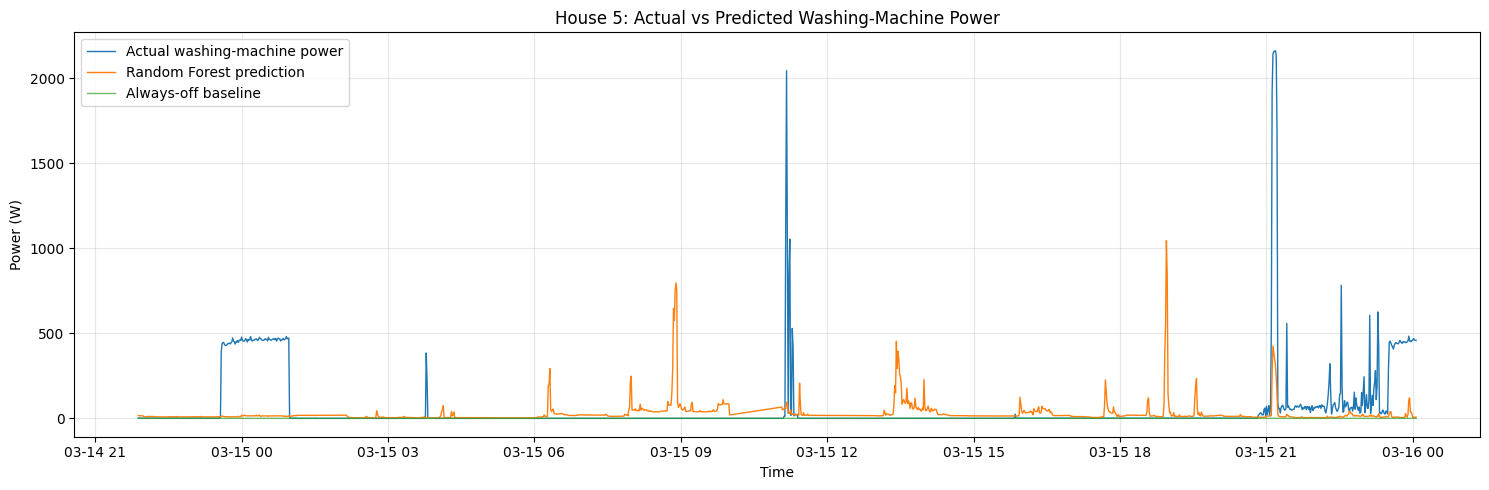

In [9]:

# CELL 9: Actual versus predicted power on test data

house = 5
pred = test_predictions[house]

# Display a representative 24-hour segment from the test period
plot_df = pd.DataFrame({
    "Actual": pred["Actual"],
    "Random Forest": pred["Random Forest"],
    "Always-off": pred["Always-off"],
    "Time": pred["Time"]
}).set_index("Time")

plot_df = plot_df.iloc[:24 * 60]

plt.figure(figsize=(15, 5))
plt.plot(
    plot_df.index, plot_df["Actual"],
    label="Actual washing-machine power", linewidth=1
)
plt.plot(
    plot_df.index, plot_df["Random Forest"],
    label="Random Forest prediction", linewidth=1
)
plt.plot(
    plot_df.index, plot_df["Always-off"],
    label="Always-off baseline", linewidth=1, alpha=0.7
)

plt.title("House 5: Actual vs Predicted Washing-Machine Power")
plt.xlabel("Time")
plt.ylabel("Power (W)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "house5_actual_vs_predicted.png",
    dpi=200, bbox_inches="tight"
)
plt.show()


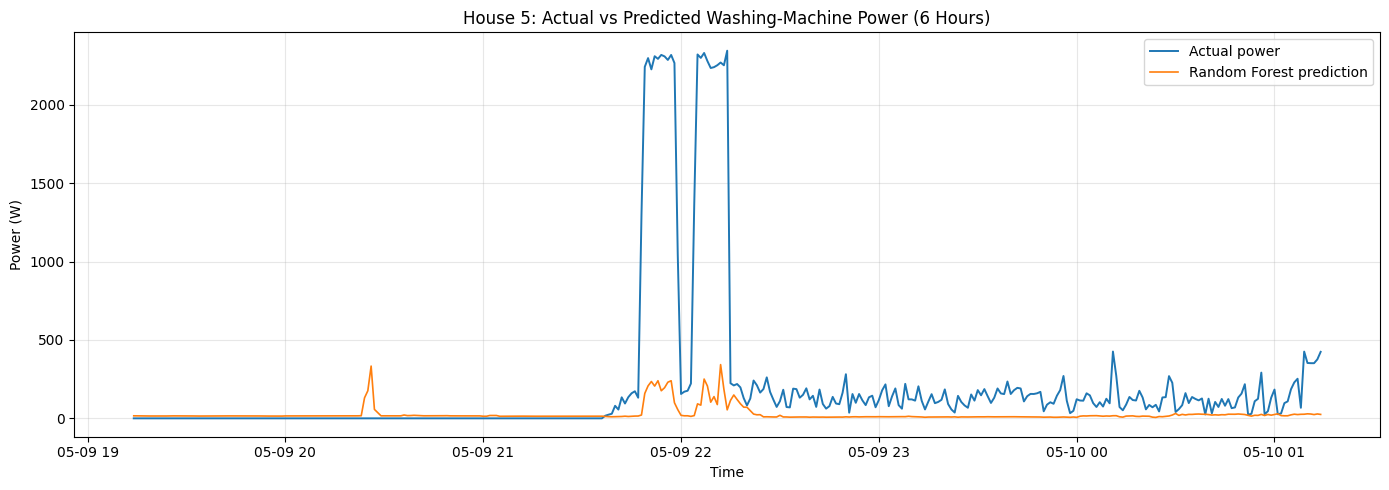

In [10]:

# CELL 11: Focused actual-vs-predicted plot for House 5

house = 5
pred = test_predictions[house]

plot_df = pd.DataFrame({
    "Actual": pred["Actual"],
    "Random Forest": pred["Random Forest"],
}, index=pd.DatetimeIndex(pred["Time"]))

# Find a six-hour window around the largest actual washing-machine reading.
peak_time = plot_df["Actual"].idxmax()
start_time = peak_time - pd.Timedelta(hours=3)
end_time = start_time + pd.Timedelta(hours=6)

focused = plot_df.loc[start_time:end_time]

plt.figure(figsize=(14, 5))
plt.plot(
    focused.index, focused["Actual"],
    label="Actual power", linewidth=1.4
)
plt.plot(
    focused.index, focused["Random Forest"],
    label="Random Forest prediction", linewidth=1.2
)

plt.title("House 5: Actual vs Predicted Washing-Machine Power (6 Hours)")
plt.xlabel("Time")
plt.ylabel("Power (W)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "house5_actual_vs_predicted_focused.png",
    dpi=200, bbox_inches="tight"
)
plt.show()


In [11]:

# Print the actual periods used for each household and split

for house in HOUSES:
    print(f"\nHouse {house}")

    for name, datasets in [
        ("Train", train_data),
        ("Validation", val_data),
        ("Test", test_data),
    ]:
        df = datasets[house]
        print(
            f"{name}: {df.index.min()} to {df.index.max()} "
            f"({len(df):,} rows)"
        )



House 1
Train: 2013-10-09 14:06:00 to 2014-12-30 22:24:00 (537,465 rows)
Validation: 2014-12-30 22:25:00 to 2015-03-26 10:24:00 (115,171 rows)
Test: 2015-03-26 10:25:00 to 2015-07-10 11:56:00 (115,172 rows)

House 2
Train: 2013-09-17 23:08:00 to 2014-12-25 07:41:00 (452,420 rows)
Validation: 2014-12-25 07:42:00 to 2015-03-03 13:17:00 (96,947 rows)
Test: 2015-03-03 13:18:00 to 2015-05-28 08:05:00 (96,948 rows)

House 3
Train: 2013-09-25 20:21:00 to 2014-12-04 13:44:00 (534,526 rows)
Validation: 2014-12-04 13:45:00 to 2015-02-24 21:02:00 (114,541 rows)
Test: 2015-02-24 21:03:00 to 2015-06-02 10:55:00 (114,542 rows)

House 5
Train: 2013-09-26 10:56:00 to 2014-12-17 05:07:00 (565,612 rows)
Validation: 2014-12-17 05:08:00 to 2015-03-14 21:52:00 (121,203 rows)
Test: 2015-03-14 21:53:00 to 2015-07-06 17:48:00 (121,203 rows)

House 6
Train: 2013-11-28 13:15:00 to 2015-01-02 12:29:00 (475,248 rows)
Validation: 2015-01-02 12:30:00 to 2015-03-16 09:54:00 (101,839 rows)
Test: 2015-03-16 09:55:00 

# Part 3: Appliance Disaggregation Model

## 1. Objective and Dataset
The objective was to estimate washing-machine power consumption at one-minute resolution using household aggregate power from the official cleaned REFIT dataset. Six households (1, 2, 3, 5, 6 and 9) were analyzed using their corresponding washing-machine appliance channels.

## 2. Methodology
Data were resampled to one-minute intervals. Features included current aggregate power, lagged readings, rolling averages, and time-of-day and day-of-week features. Missing readings were excluded rather than filled with zero.

A Random Forest Regressor was trained separately for each household and compared with two baselines: an always-off model and a time-based usage-profile model.

Each household was split chronologically into 70% training, 15% validation and 15% testing. This evaluates performance on later observations and reduces temporal data leakage. The exact periods used are recorded in the notebook.

## 3. Evaluation and Results
The models were evaluated using MAE, RMSE, R² and active-period MAE, calculated when actual washing-machine power exceeded 10 W.

| Metric | Always-off | Usage-profile | Random Forest |
|---|---:|---:|---:|
| MAE (W) | **19.704** | 33.361 | 25.160 |
| RMSE (W) | 169.455 | 166.790 | **141.299** |
| R² | -0.014 | 0.018 | **0.295** |
| Active-period MAE (W) | 404.114 | 371.022 | **297.896** |

Random Forest achieved the lowest RMSE and active-period MAE, but the always-off baseline achieved the lowest overall MAE. This highlights the importance of evaluating both inactive and active periods.

## 4. Actual vs Predicted
The House 5 test plot shows that Random Forest captures some power patterns but underestimates several high-power washing-machine peaks. It also occasionally predicts power when actual washing-machine consumption is low.

## 5. Failure Cases and Limitations
- **Missed high-power peaks:** The model substantially underestimates some washing-machine events reaching approximately 2,200 W, potentially because such events are difficult to learn accurately from the training data.
- **False-positive predictions:** Other household appliances can produce aggregate power patterns similar to those of a washing machine, causing the model to predict washing-machine activity when the actual target is low.

## 6. Conclusion
Random Forest improved RMSE, R² and active-period estimation compared with the baselines, but did not achieve the lowest overall MAE. The results demonstrate that appliance disaggregation from aggregate power is challenging, particularly when appliances operate simultaneously or produce similar power patterns.
